# 07 — Colour constancy and colour augmentation (round 5): a pre-registered negative result

**Hypothesis** (`research/round5_plan.md`, written before the runs): part of the CV → test drop comes from acquisition shift
(other clinics and devices in the test set). **Shades-of-Grey colour constancy** (p = 6, as in the ISIC 2019 winner) and
**stronger colour augmentation** (jitter 0.3 / 0.3 / 0.3, hue 0.1) should therefore help on test.

**Design.** One factor at a time on the optimised ResNet-50 (448 px, plain CE, 30 epochs, 5 folds, TTA-20 + logit adjustment):
the primary run combines both changes; two ablations isolate each. CV (HAM10000 only) cannot see the shift, so it is a
**non-inferiority check** (margin 0.005); adoption for later rounds depends on CV alone, and the test comparison is a single
pre-registered contrast.

**Reproduce:** `salloc ... srun ... bash slurm/run_jobs_node.sh slurm/jobs/round5_train.txt slurm/jobs/round5_eval.txt`
(~85 min), then `python research/round5_analysis.py`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

HWX_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWX_DIR))
from isic import analysis as A
from isic.data import CLASSES, ShadesOfGray, load_split

pd.set_option("display.width", 200)
RUN_TRAINING = False   # True on a GPU node: re-create one fold of the primary variant (~18 min)

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWX_DIR)

if RUN_TRAINING:
    run("python train_classifier.py --run-name resnet50_cc_coloraug_res448 --img-size 448 --color-constancy --augment color --fold 0")
    run("python evaluate_tta.py resnet50_cc_coloraug_res448 --crops 5 --folds 0")
    run("python posthoc_logit_adjustment.py resnet50_cc_coloraug_res448_tta20")

## 1. What Shades of Grey does to the images, and how different train and test colours are

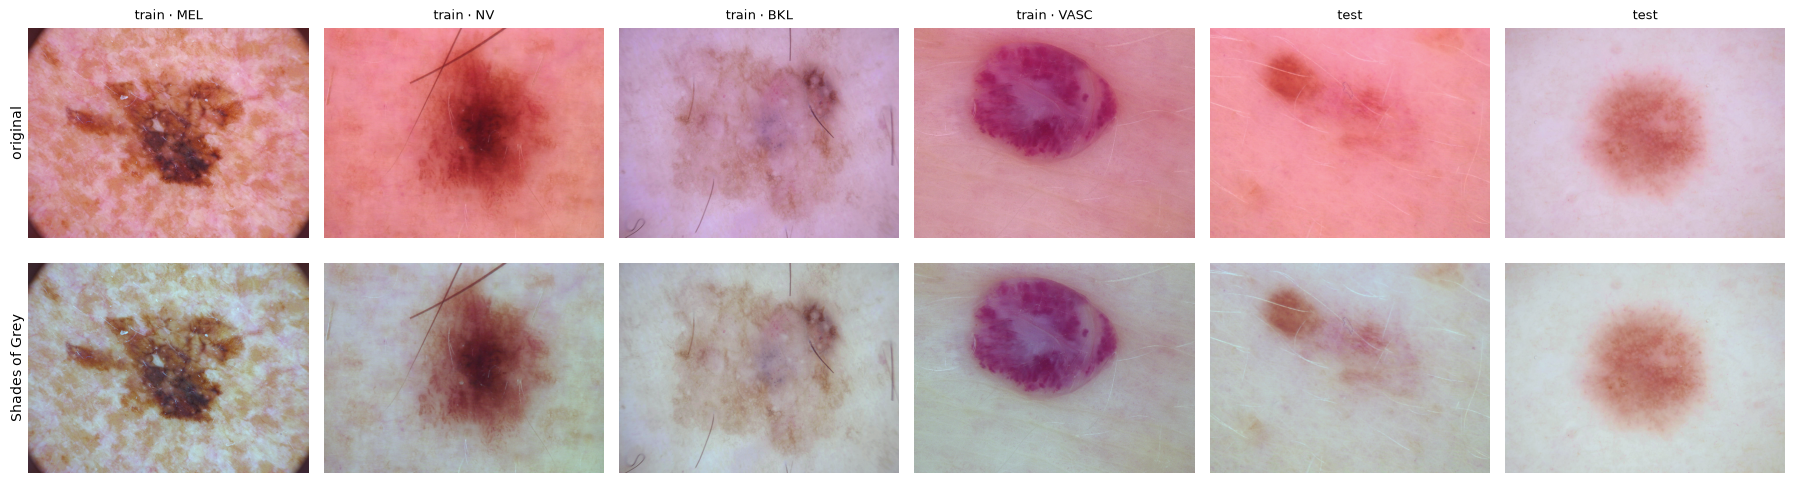

In [2]:
sog = ShadesOfGray()
tr, te = load_split("train"), load_split("test")
examples = [tr[tr.dx == c].iloc[0].path for c in ["MEL", "NV", "BKL", "VASC"]] + [te.iloc[i].path for i in (0, 1)]
fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 5.2))
for j, p in enumerate(examples):
    im = Image.open(p).convert("RGB")
    axes[0, j].imshow(im); axes[1, j].imshow(sog(im))
    axes[0, j].set_title(("train · " + tr.set_index("path").dx.get(p, "")) if p in set(tr.path) else "test", fontsize=9)
    for a in axes[:, j]: a.axis("off")
axes[0, 0].text(-40, 225, "original", rotation=90, va="center"); axes[1, 0].text(-40, 225, "Shades of Grey", rotation=90, va="center")
plt.tight_layout()

In [3]:
def chroma(df, cc, n=300):
    out = []
    for p in df.sample(n, random_state=0).path:
        im = Image.open(p).convert("RGB")
        x = np.asarray(sog(im) if cc else im, dtype=np.float32).mean((0, 1))
        out.append(x / x.sum())
    return np.array(out)
rows = []
for cc in (False, True):
    a, b = chroma(tr, cc), chroma(te, cc)
    rows.append({"images": "Shades of Grey" if cc else "original", "train chromaticity spread (r,g,b)": a.std(0).round(4),
                 "test chromaticity spread": b.std(0).round(4), "train-test mean chromaticity gap": np.abs(a.mean(0) - b.mean(0)).sum().round(4)})
pd.DataFrame(rows).set_index("images")

,"train chromaticity spread (r,g,b)",test chromaticity spread,train-test mean chromaticity gap
images,,,
original,"[0.0422, 0.0195, 0.0277]","[0.0427, 0.0206, 0.0268]",0.0033
Shades of Grey,"[0.0095, 0.0044, 0.0068]","[0.0091, 0.0046, 0.0065]",0.0004


## 2. Results (pre-registered analysis)

In [4]:
BASE = "resnet50_ce_res448_tta20_la"
RUNS = {"baseline (no CC, basic aug)": BASE,
        "primary: CC + strong colour aug": "resnet50_cc_coloraug_res448_tta20_la",
        "ablation: CC only": "resnet50_cc_res448_tta20_la",
        "ablation: strong colour aug only": "resnet50_coloraug_res448_tta20_la"}
display(A.summary(list(RUNS.values()), names=list(RUNS)))
A.paired_table(list(RUNS.values())[1:], BASE, names=list(RUNS)[1:])

,bal_acc,acc,f1,auc,mel_sens,mel_spec,ensemble_bal_acc,n_folds
"baseline (no CC, basic aug)",0.835 ± 0.013,0.803 ± 0.020,0.720 ± 0.029,0.973 ± 0.003,0.759 ± 0.032,0.925 ± 0.007,0.87,5
primary: CC + strong colour aug,0.818 ± 0.016,0.802 ± 0.012,0.722 ± 0.008,0.971 ± 0.003,0.771 ± 0.025,0.906 ± 0.016,0.844,5
ablation: CC only,0.803 ± 0.009,0.823 ± 0.030,0.747 ± 0.025,0.969 ± 0.005,0.744 ± 0.055,0.919 ± 0.028,0.839,5
ablation: strong colour aug only,0.816 ± 0.003,0.812 ± 0.023,0.728 ± 0.023,0.971 ± 0.002,0.753 ± 0.027,0.922 ± 0.018,0.852,5


,cv_bal_acc,cv_mel_sens,cv_auc,test_bal_acc,test_mel_sens,test_auc
primary: CC + strong colour aug,-0.005 ± 0.012 (2/5),+0.031 ± 0.042 (3/5),-0.002 ± 0.004 (1/5),-0.016 ± 0.020 (0/5),+0.012 ± 0.044 (2/5),-0.002 ± 0.004 (2/5)
ablation: CC only,-0.009 ± 0.019 (2/5),-0.013 ± 0.038 (3/5),+0.001 ± 0.005 (4/5),-0.032 ± 0.022 (0/5),-0.015 ± 0.036 (1/5),-0.004 ± 0.006 (1/5)
ablation: strong colour aug only,-0.013 ± 0.018 (2/5),+0.013 ± 0.041 (3/5),+0.001 ± 0.004 (2/5),-0.018 ± 0.011 (0/5),-0.006 ± 0.025 (1/5),-0.001 ± 0.003 (2/5)


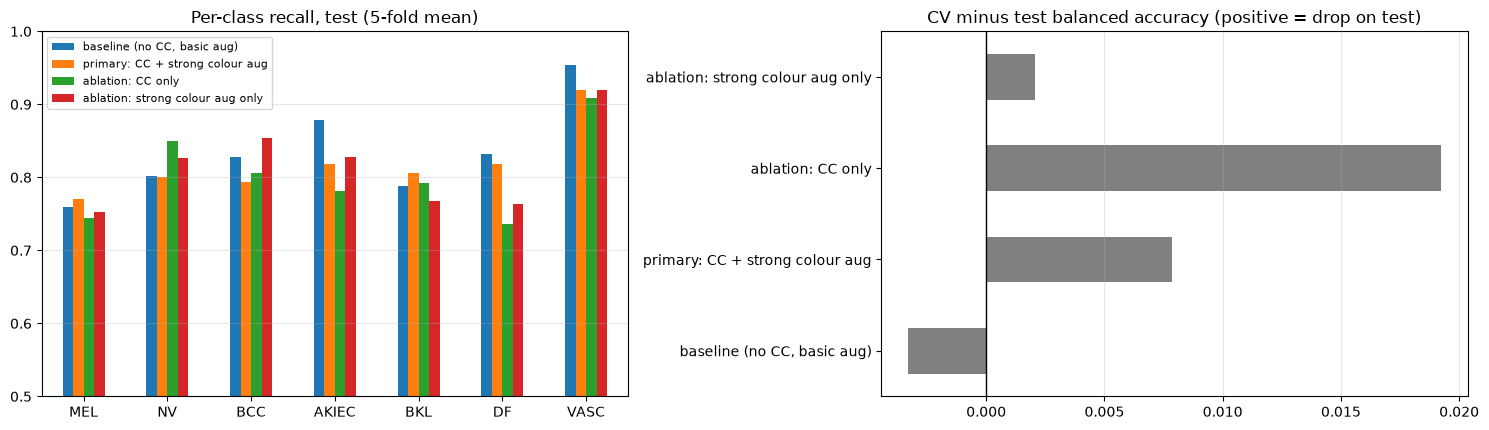

In [5]:
rec = pd.DataFrame({n: A.per_class_recall(r) for n, r in RUNS.items()})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
rec.plot.bar(ax=axes[0], rot=0); axes[0].set_ylim(0.5, 1); axes[0].grid(axis="y", alpha=.3)
axes[0].set_title("Per-class recall, test (5-fold mean)"); axes[0].legend(fontsize=8)
gap = pd.Series({n: A.per_fold(r, "cv_val").bal_acc.mean() - A.per_fold(r).bal_acc.mean() for n, r in RUNS.items()})
gap.plot.barh(ax=axes[1], color="grey"); axes[1].axvline(0, c="k", lw=1)
axes[1].set_title("CV minus test balanced accuracy (positive = drop on test)"); axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()

## Takeaways
* **Hypothesis rejected.** Every colour variant is worse than the baseline on the test set on **all 5 folds** (CC + strong
  aug −0.016, CC only −0.032, strong aug only −0.019) and none passes the CV non-inferiority check, so nothing is adopted.
* **Colour is signal here, not just nuisance.** Vascular lesions are red, keratoses brown, dermatofibromas pinkish-brown;
  normalising the global colour cast or jittering hue by ±0.1 removes information the classifier uses. HAM10000 and the test
  set also differ little in mean colour (chromaticity gap 0.003–0.012 before CC, depending on the image sample; table above),
  so there was little shift for CC to fix.
* **The premise was only partly right.** The optimised ResNet-50 has no CV → test drop (test is 0.003 *higher*); the drop we
  targeted belonged to other models. Pre-registering the rule kept us from searching on the test set for a colour setting that
  happens to work.